# Chess Data Analysis Pipeline

Tento notebook replikuje logiku ze souboru `main.py` a `data_analysis.py` a rozděluje ji do samostatných bloků pro snadnější spouštění a testování jednotlivých částí procesu analýzy šachových her.

## Příprava dat

### Konfigurace a příprava adresářů

In [15]:
import os
import json
import os
from scipy.stats import pearsonr
import pandas as pd
from tqdm import tqdm
from dotenv import load_dotenv
import game_load
import stockfish_eval
import data_analysis

load_dotenv()

True

In [16]:
CHESS_USER = os.getenv("CHESS_USER")
stockfish_path = "stockfish/stockfish-windows-x86-64-avx2.exe"

if CHESS_USER:
    path = CHESS_USER + "_data"
    if not os.path.isdir(path):
        os.mkdir(path)
        print(f"Vytvořena datová složka uživatele: {path}")
    print(f"Pracuji s uživatelem: {CHESS_USER}")
else:
    print("CHESS_USER není nastaven v .env souboru.")

Pracuji s uživatelem: viki953


### 1. Načtení her (Download Games)

In [17]:
def load_games(base_path):
    games_dir = os.path.join(base_path, "games")
    if not os.path.isdir(games_dir):
        os.mkdir(games_dir)

    games_count = game_load.fetch_chess_games(CHESS_USER, games_dir)
    print(f"Staženo {games_count} her uživatele {CHESS_USER}")
    return games_dir

games_path = os.getenv("GAMES_PATH")

if not games_path or not os.path.isdir(games_path):
    print("Games path not found in env or dir missing. Loading games...")
    games_path = load_games(path)
else:
    print(f"Hry již nalezeny v: {games_path}")

Hry již nalezeny v: viki953_data\games


### 2. Analýza her (Stockfish Evaluation)

In [18]:
def analyze_games(games_source, base_path, engine_path):
    analyzed_dir = os.path.join(base_path, "games_analyzed")
    if not os.path.isdir(analyzed_dir):
        os.mkdir(analyzed_dir)

    print("Spouštím Stockfish analýzu...")
    count = stockfish_eval.analyze_archives(games_source, analyzed_dir, engine_path)
    print(f"Her analyzováno: {count}.")
    return analyzed_dir

analyzed_path = os.getenv("ANALYZED_PATH")

# Pokud není cesta v ENV, nebo složka neexistuje, je možné, že chceme spustit analýzu.
# Zde je to zakomentované, aby se nespustilo omylem (trvá dlouho).
# Odkomentujte pro spuštění:

# if not analyzed_path or not os.path.isdir(analyzed_path):
#     analyzed_path = analyze_games(games_path, path, stockfish_path)
# else:
#     print(f"Analyzovaná data nalezená v: {analyzed_path}")

# Pro účely notebooku, pokud cesta není definovaná, zkusíme default:
if not analyzed_path:
    analyzed_path = os.path.join(path, "games_analyzed")
    print("using default fallback path")

print(f"Cesta k analyzovaným datům: {analyzed_path}")

Cesta k analyzovaným datům: viki953_data\games_analyzed


### 3. Analýza Dat (Data Analysis & Statistics)

In [19]:
df_games, df_moves = pd.DataFrame(), pd.DataFrame()
if not os.path.isdir(analyzed_path):
    print(f"Adresář {analyzed_path} neexistuje. Nejdříve spusťte analýzu her.")
elif len(os.listdir(analyzed_path)) == 0:
    print(f"Adresář {analyzed_path} je prázdný. Nejdříve spusťte analýzu her.")
else:
    df_games, df_moves = data_analysis.load_all_data(analyzed_path)

Loading data from 8 files...
Loaded 2164 games and 133677 moves.


## 4. Vizualizace a Statistiky

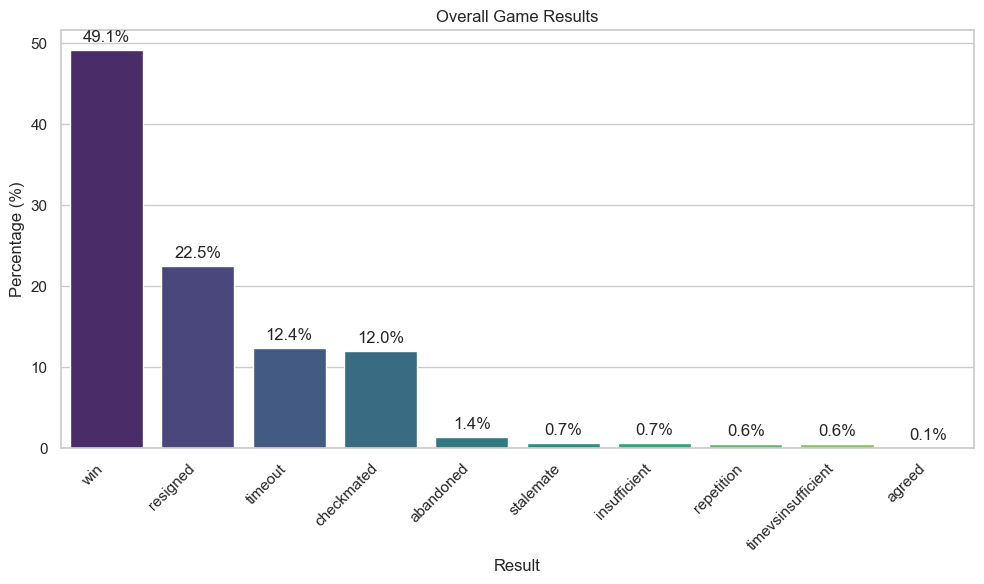

In [12]:
if not df_games.empty:
    data_analysis.plot_winrate_overall(df_games)

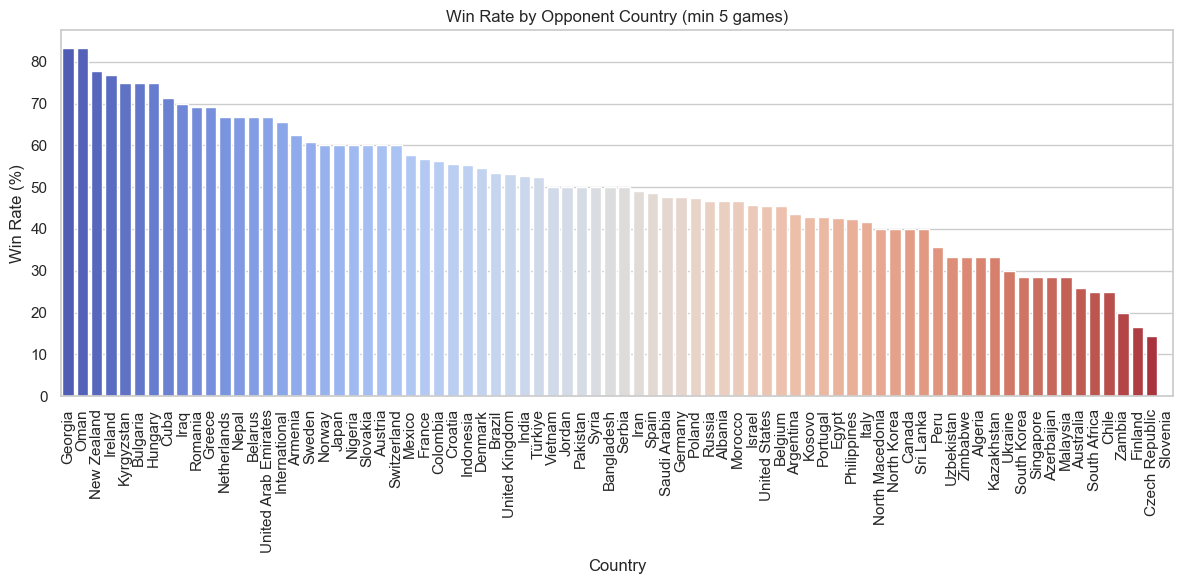

In [12]:
if not df_games.empty:
    data_analysis.plot_country_winrate(df_games)

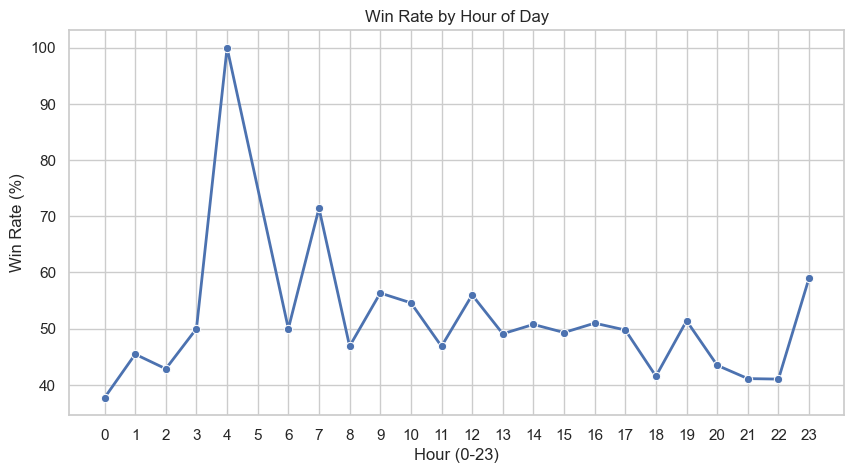

In [13]:
if not df_games.empty:
    data_analysis.plot_hourly_winrate(df_games)

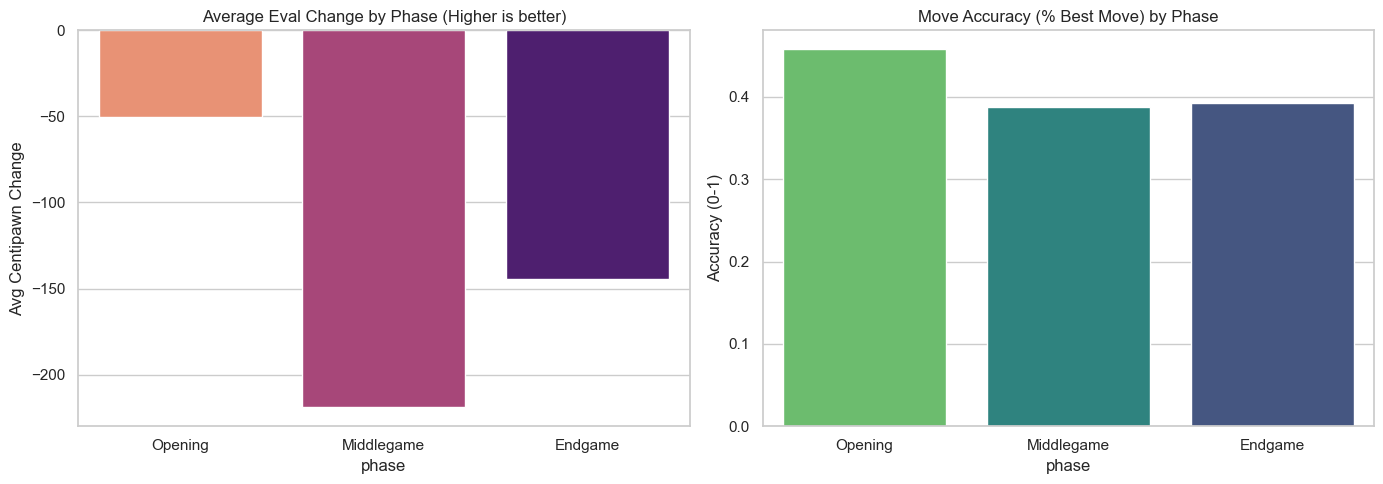


--- Critical Pieces by Phase (Worst Avg Eval Change) ---

Opening:
moved_piece
Q   -69.774972
B   -59.876001
N   -57.187272
Name: move_eval_change, dtype: float64


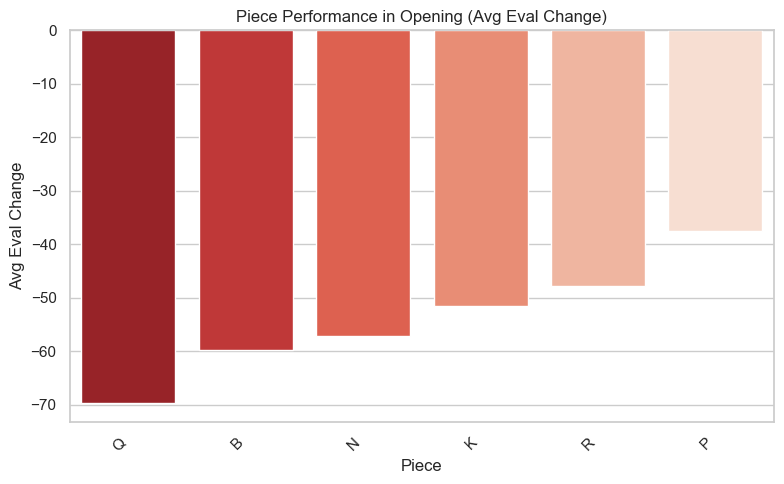


Middlegame:
moved_piece
K   -301.715525
R   -250.159915
Q   -223.274727
Name: move_eval_change, dtype: float64


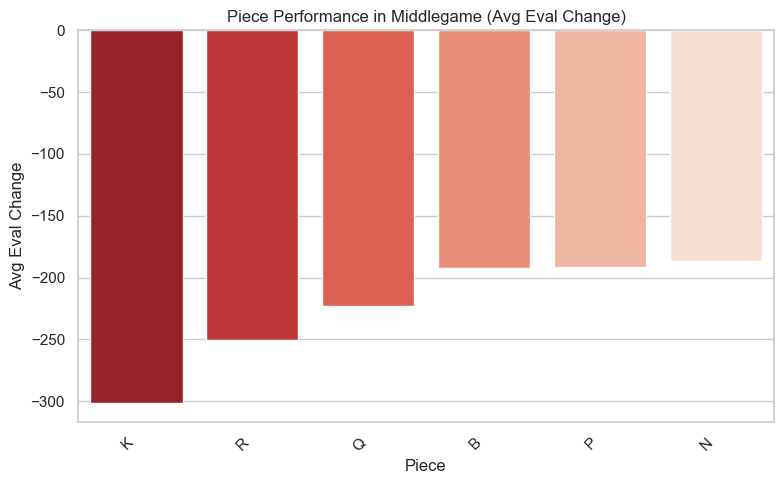


Endgame:
moved_piece
B   -337.660634
Q   -244.061043
K   -133.974081
Name: move_eval_change, dtype: float64


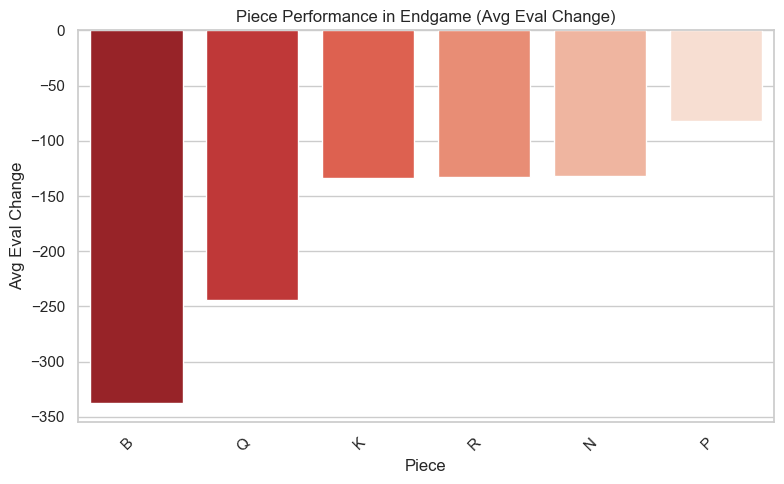

In [20]:
if not df_moves.empty:
    data_analysis.analyze_game_phases(df_moves)

Correlation between Time Used and Move Quality (Eval Change): -0.0404


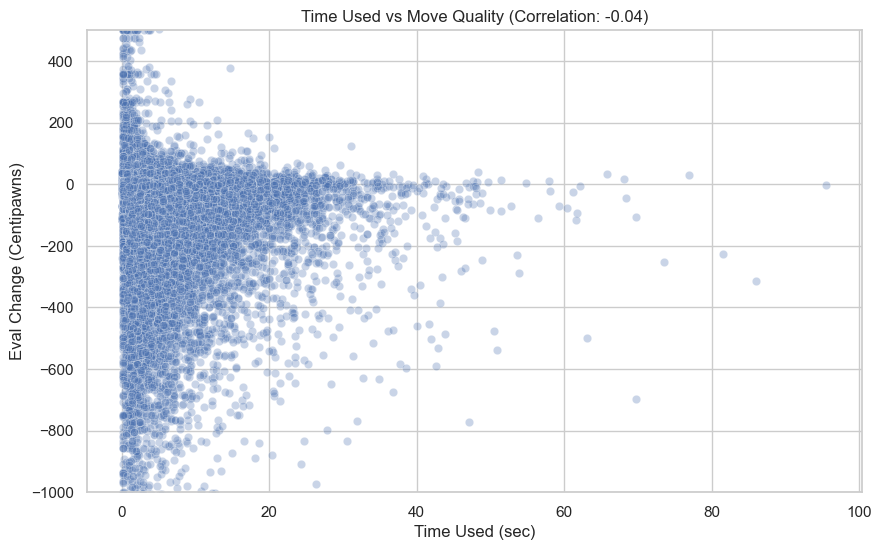

In [21]:
if not df_moves.empty:
    data_analysis.plot_time_vs_quality(df_moves)

In [ ]:
if not df_games.empty:
    data_analysis.analyze_castling(df_games)

In [ ]:
if not df_moves.empty:
    data_analysis.analyze_blunders(df_moves)

In [ ]:
if not df_moves.empty:
    data_analysis.analyze_missed_mates(df_moves)

In [ ]:
if not df_games.empty:
    data_analysis.plot_opening_winrate(df_games)

In [ ]:
if not df_games.empty and not df_moves.empty:
    data_analysis.analyze_ragequits(df_games, df_moves)

Niní máme data načtena v `df_games` a `df_moves`. `df_games` obsahuje informace o jednotlivých hrách a `df_moves` obsahuje podrobnosti o jednotlivých tazích extrahovaných ze všech her s dodatečným atributem `games_url` odkazující na původní hru z `df_games`, ve které byl tah zahrán a `players_move` označující za se jedná o tah analyzovaného hráče.